# Практичне заняття № 8 — Метод DBSCAN і A/B-тестування

**Завдання.** На довільному датасеті дослідити роботу DBSCAN і A/B-тестування
([Kaggle: security](https://www.kaggle.com/datasets?search=security)).

Робота складається з двох незалежних частин: **DBSCAN** — алгоритм кластеризації
на основі щільності, і **A/B-тестування** — статистична перевірка гіпотез. Спільне
між ними те, що обидва відповідають на питання «чи є тут структура / різниця, чи
це випадковість».

**Датасет: UGRansome** — той самий, що в практичних заняттях № 2, № 3, № 5 і № 6.
У занятті № 6 на ньому вже досліджено k-середніх та ієрархічну кластеризацію, тож
DBSCAN можна порівняти безпосередньо.

---

# Частина 1. DBSCAN

## Ідея методу

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) визначає
кластери як **області високої щільності**, розділені областями низької. Кожна
точка отримує одну з трьох ролей:

- **ядрова** (core) — у її $\varepsilon$-околі не менше `min_samples` точок;
- **межова** (border) — потрапляє в окіл ядрової, але сама кореневою не є;
- **шум** (noise) — не належить жодному кластеру.

На відміну від k-середніх, DBSCAN **не вимагає задавати кількість кластерів**
наперед, знаходить кластери **довільної форми** і явно позначає викиди. Остання
властивість цікава для аналізу кіберінцидентів: точки-шум є природними
кандидатами в аномалії.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('ugransome.csv', 'nkongolo/ugransome-dataset',
     'final(2).csv', 14, 149043, 'utf-8')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/ugransome.csv (10.0 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import adjusted_rand_score, silhouette_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

N_MAIN = 15000

## 1.1 Дані та вибір параметра eps

In [3]:
df = pd.read_csv("data/ugransome.csv")
y_all = df["Prediction"].copy()
X_all = df.drop(columns=["Prediction"]).copy()
for col in X_all.select_dtypes(include=["object", "string"]).columns:
    X_all[col] = X_all[col].astype("category").cat.codes

X, _, y_true, _ = train_test_split(X_all, y_all, train_size=N_MAIN,
                                   random_state=RANDOM_STATE, stratify=y_all)
X = X.reset_index(drop=True); y_true = y_true.reset_index(drop=True)
Z = StandardScaler().fit_transform(X)
print(f"Розмір: {Z.shape}, класи: {dict(y_true.value_counts())}")

Розмір: (15000, 13), класи: {'S': np.int64(6681), 'A': np.int64(4283), 'SS': np.int64(4036)}


In [4]:
# Стандартний спосіб вибору eps — графік k-відстаней:
# для кожної точки беремо відстань до k-го сусіда, сортуємо і шукаємо «коліно»
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
dists, _ = nn.kneighbors(Z)
kdist = np.sort(dists[:, -1])

pcts = {p: float(np.percentile(kdist, p)) for p in [50, 75, 90, 95, 99]}
print("Перцентилі відстані до 10-го сусіда:")
for p, v in pcts.items():
    print(f"  {p}%: {v:.2f}")

Перцентилі відстані до 10-го сусіда:
  50%: 0.85
  75%: 1.21
  90%: 1.56
  95%: 1.83
  99%: 2.34


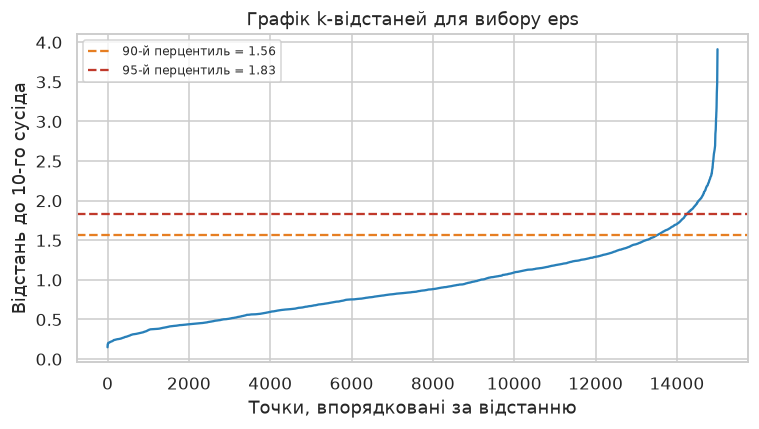

In [5]:
# --- Рисунок 1: графік k-відстаней ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(len(kdist)), kdist, color="#2980b9")
for p, col in [(90, "#e67e22"), (95, "#c0392b")]:
    ax.axhline(pcts[p], color=col, linestyle="--", label=f"{p}-й перцентиль = {pcts[p]:.2f}")
ax.set_xlabel("Точки, впорядковані за відстанню")
ax.set_ylabel(f"Відстань до {MIN_SAMPLES}-го сусіда")
ax.set_title("Графік k-відстаней для вибору eps")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "01-kdist.png", bbox_inches="tight")
plt.show()

## 1.2 Сітка параметрів

In [6]:
grid_rows = []
for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0]:
    for ms in [5, 10, 25]:
        db = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit(Z)
        lab = db.labels_
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).mean()
        grid_rows.append({
            "eps": eps, "min_samples": ms,
            "Кластерів": n_clusters, "Шуму": noise,
            "ARI": adjusted_rand_score(y_true, lab),
        })

db_df = pd.DataFrame(grid_rows)
db_df.to_csv("data/dbscan-grid.csv", index=False)
best = db_df.loc[db_df["ARI"].idxmax()]
print(f"Найкращий ARI = {best['ARI']:.4f} при eps={best['eps']}, min_samples={int(best['min_samples'])}")
print(f"Для порівняння, k-середніх у ПЗ № 6 дали ARI = 0.2010")
db_df.round(4)

Найкращий ARI = 0.0837 при eps=1.5, min_samples=5
Для порівняння, k-середніх у ПЗ № 6 дали ARI = 0.2010


,eps,min_samples,Кластерів,Шуму,ARI
0,0.50,5,627,0.4387,-0.0068
1,0.50,10,149,0.7272,-0.0318
2,0.50,25,23,0.9351,-0.0214
3,0.75,5,583,0.2323,0.0112
4,0.75,10,229,0.4782,-0.0018
5,0.75,25,43,0.7818,-0.0267
6,1.00,5,445,0.1095,0.0237
7,1.00,10,226,0.2707,0.0197
8,1.00,25,67,0.5625,-0.0032
9,1.25,5,222,0.0462,0.0492


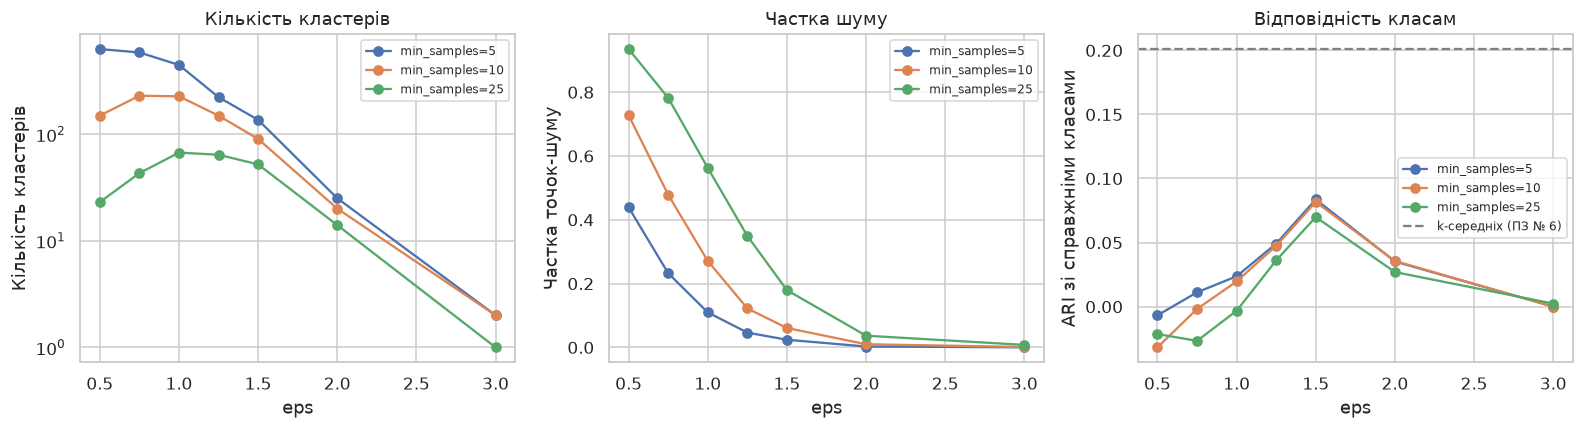

In [7]:
# --- Рисунок 2: поведінка DBSCAN ---
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))
for ms, grp in db_df.groupby("min_samples"):
    axes[0].plot(grp["eps"], grp["Кластерів"], "o-", label=f"min_samples={ms}")
    axes[1].plot(grp["eps"], grp["Шуму"], "o-", label=f"min_samples={ms}")
    axes[2].plot(grp["eps"], grp["ARI"], "o-", label=f"min_samples={ms}")
axes[0].set_yscale("log"); axes[0].set_ylabel("Кількість кластерів")
axes[1].set_ylabel("Частка точок-шуму")
axes[2].set_ylabel("ARI зі справжніми класами")
axes[2].axhline(0.2010, color="gray", linestyle="--", label="k-середніх (ПЗ № 6)")
for ax, t in zip(axes, ["Кількість кластерів", "Частка шуму", "Відповідність класам"]):
    ax.set_xlabel("eps"); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "02-dbscan-grid.png", bbox_inches="tight")
plt.show()

## 1.3 Де DBSCAN справді сильніший за k-середніх

На UGRansome DBSCAN програє. Щоб показати, **де** метод дійсно виграє, порівняємо
обидва алгоритми на синтетичних наборах з неопуклими кластерами — саме на таких
формах k-середніх принципово безсилий, бо шукає лише кулясті скупчення.

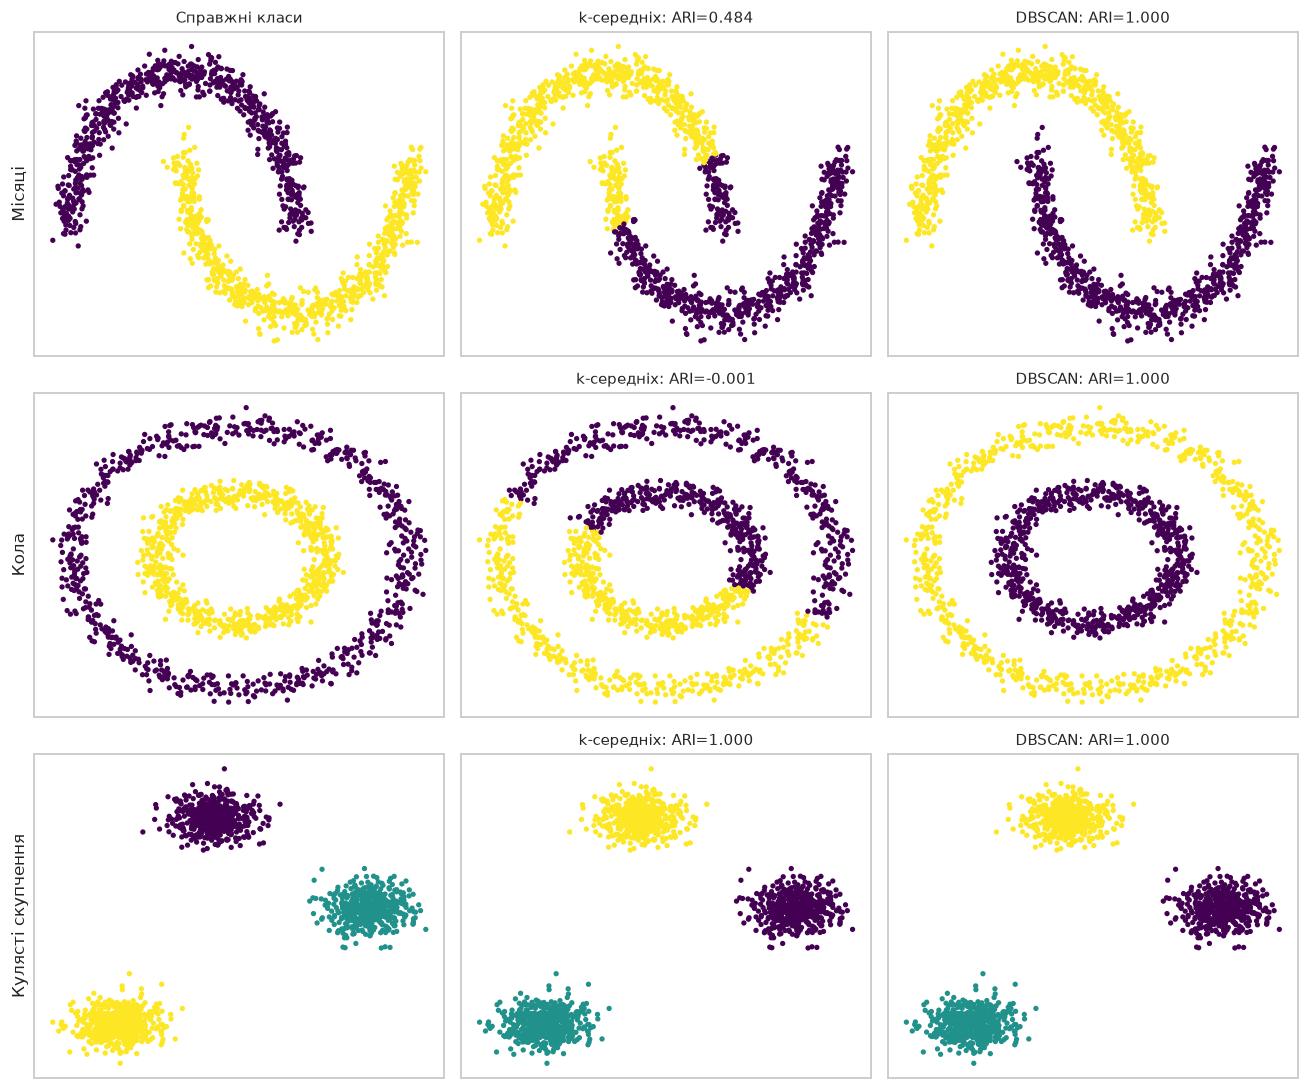

,k-середніх (ARI),DBSCAN (ARI)
Набір,,
Місяці,0.4841,1.0
Кола,-0.0006,1.0
Кулясті скупчення,1.0000,1.0


In [8]:
synth = {
    "Місяці": make_moons(n_samples=1500, noise=0.06, random_state=RANDOM_STATE),
    "Кола": make_circles(n_samples=1500, noise=0.05, factor=0.5, random_state=RANDOM_STATE),
    "Кулясті скупчення": make_blobs(n_samples=1500, centers=3, cluster_std=1.0,
                                     random_state=RANDOM_STATE),
}

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
synth_rows = []
for r, (name, (Xs_, ys_)) in enumerate(synth.items()):
    Zs = StandardScaler().fit_transform(Xs_)
    km = KMeans(n_clusters=len(set(ys_)), random_state=RANDOM_STATE, n_init=10).fit(Zs)
    eps_ = 0.3 if name != "Кулясті скупчення" else 0.4
    db = DBSCAN(eps=eps_, min_samples=8).fit(Zs)

    a_km = adjusted_rand_score(ys_, km.labels_)
    a_db = adjusted_rand_score(ys_, db.labels_)
    synth_rows.append({"Набір": name, "k-середніх (ARI)": a_km, "DBSCAN (ARI)": a_db})

    axes[r, 0].scatter(Zs[:, 0], Zs[:, 1], c=ys_, s=6, cmap="viridis")
    axes[r, 0].set_ylabel(name, fontsize=11)
    axes[r, 1].scatter(Zs[:, 0], Zs[:, 1], c=km.labels_, s=6, cmap="viridis")
    axes[r, 2].scatter(Zs[:, 0], Zs[:, 1], c=db.labels_, s=6, cmap="viridis")
    axes[r, 1].set_title(f"k-середніх: ARI={a_km:.3f}", fontsize=10)
    axes[r, 2].set_title(f"DBSCAN: ARI={a_db:.3f}", fontsize=10)
    for col in range(3):
        axes[r, col].set_xticks([]); axes[r, col].set_yticks([])
axes[0, 0].set_title("Справжні класи", fontsize=10)
plt.tight_layout()
plt.savefig(ASSETS / "03-synthetic.png", bbox_inches="tight")
plt.show()

synth_df = pd.DataFrame(synth_rows).set_index("Набір")
synth_df.round(4)

## 1.4 DBSCAN як детектор аномалій

Найпрактичніше застосування DBSCAN для аналізу кіберінцидентів — не кластеризація
як така, а **позначення точок-шуму**. Перевіримо, чи справді вони відповідають
класу `A` (Anomaly).

In [9]:
base_rate = (y_true == "A").mean()
anom_rows = []
for eps in [0.75, 1.0, 1.25, 1.5, 2.0]:
    db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit(Z)
    noise = db.labels_ == -1
    if noise.sum() == 0:
        continue
    frac_A = (y_true[noise] == "A").mean()
    anom_rows.append({"eps": eps, "Частка шуму": noise.mean(),
                      "Класу A серед шуму": frac_A,
                      "Lift": frac_A / base_rate})

anom_df = pd.DataFrame(anom_rows)
anom_df.to_csv("data/anomaly.csv", index=False)
print(f"Базова частка класу A: {base_rate:.4f}")
anom_df.round(4)

Базова частка класу A: 0.2855


,eps,Частка шуму,Класу A серед шуму,Lift
0,0.75,0.4782,0.3936,1.3783
1,1.00,0.2707,0.4063,1.4230
2,1.25,0.1219,0.3920,1.3729
3,1.50,0.0607,0.3688,1.2917
4,2.00,0.0097,0.3082,1.0795


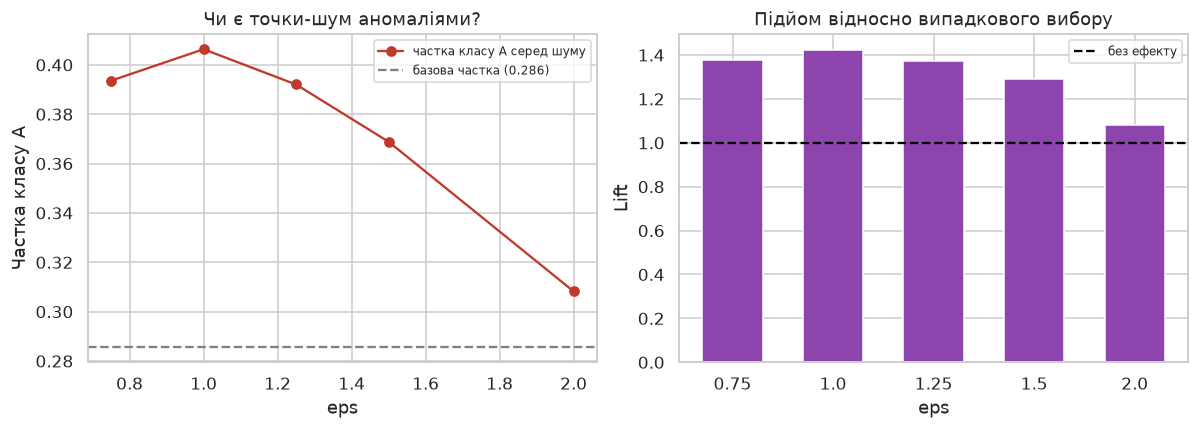

In [10]:
# --- Рисунок 4: шум як детектор аномалій ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(anom_df["eps"], anom_df["Класу A серед шуму"], "o-", color="#c0392b",
             label="частка класу A серед шуму")
axes[0].axhline(base_rate, color="gray", linestyle="--", label=f"базова частка ({base_rate:.3f})")
axes[0].set_xlabel("eps"); axes[0].set_ylabel("Частка класу A")
axes[0].set_title("Чи є точки-шум аномаліями?"); axes[0].legend(fontsize=8)

axes[1].bar(anom_df["eps"].astype(str), anom_df["Lift"], color="#8e44ad", width=0.6)
axes[1].axhline(1.0, color="black", linestyle="--", label="без ефекту")
axes[1].set_xlabel("eps"); axes[1].set_ylabel("Lift")
axes[1].set_title("Підйом відносно випадкового вибору"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "04-anomaly.png", bbox_inches="tight")
plt.show()

---

# Частина 2. A/B-тестування

## Постановка

A/B-тестування — статистична перевірка того, чи є спостережувана різниця між двома
варіантами **реальною**, чи вкладається у випадкові коливання.

Практична задача: у систему виявлення інцидентів пропонується замінити наявну
модель (**варіант A** — дерево рішень) на нову (**варіант B** — випадковий ліс).
Обидві застосовуються до одного потоку подій. Питання: чи справді B краща, чи
різниця випадкова?

**Нульова гіпотеза $H_0$:** частки правильних рішень однакові, $p_A = p_B$.
**Альтернативна $H_1$:** $p_A \ne p_B$.

In [11]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y_true, test_size=0.3,
                                          random_state=RANDOM_STATE, stratify=y_true)
model_A = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_tr, y_tr)
model_B = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr)

pred_A, pred_B = model_A.predict(X_te), model_B.predict(X_te)
correct_A, correct_B = (pred_A == y_te).values, (pred_B == y_te).values
n = len(y_te)
pA, pB = correct_A.mean(), correct_B.mean()

print(f"Розмір тестової вибірки: n = {n}")
print(f"Варіант A (дерево, depth=5): {correct_A.sum()} правильних, частка {pA:.4f}")
print(f"Варіант B (ліс, 50 дерев):   {correct_B.sum()} правильних, частка {pB:.4f}")
print(f"Спостережувана різниця: {pB - pA:+.4f}")

Розмір тестової вибірки: n = 4500
Варіант A (дерево, depth=5): 4121 правильних, частка 0.9158
Варіант B (ліс, 50 дерев):   4449 правильних, частка 0.9887
Спостережувана різниця: +0.0729


## 2.1 Z-тест для двох часток

In [12]:
# Класичний двовибірковий z-тест для часток
p_pool = (correct_A.sum() + correct_B.sum()) / (2 * n)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n + 1/n))
z = (pB - pA) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

# Довірчий інтервал для різниці (без об'єднаної оцінки)
se_diff = np.sqrt(pA*(1-pA)/n + pB*(1-pB)/n)
ci = (pB - pA - 1.96*se_diff, pB - pA + 1.96*se_diff)

print(f"Об'єднана частка p̂ = {p_pool:.4f}")
print(f"z = {z:.4f}")
print(f"p-значення = {p_value:.3e}")
print(f"95 % довірчий інтервал різниці: [{ci[0]:+.4f}, {ci[1]:+.4f}]")
print()
print("Висновок:", "H0 відхилено — різниця статистично значуща"
      if p_value < 0.05 else "підстав відхилити H0 немає")

Об'єднана частка p̂ = 0.9522
z = 16.2095
p-значення = 0.000e+00
95 % довірчий інтервал різниці: [+0.0642, +0.0816]

Висновок: H0 відхилено — різниця статистично значуща


## 2.2 Критерій Мак-Немара — коректніший для цієї задачі

Z-тест припускає **незалежні вибірки**. Але тут обидві моделі оцінюються на
**тих самих** прикладах, тобто вибірки парні. Ігнорування парності знижує
чутливість тесту.

Критерій Мак-Немара враховує лише **розбіжні пари** — випадки, де моделі дали
різні відповіді:

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$$

де $b$ — випадки «A правильна, B помилилась», $c$ — навпаки.

In [13]:
both_right = int((correct_A & correct_B).sum())
only_A = int((correct_A & ~correct_B).sum())
only_B = int((~correct_A & correct_B).sum())
both_wrong = int((~correct_A & ~correct_B).sum())

# Рядок — стан B, стовпець — стан A. only_B = «B права, A помилилась»,
# тому він належить клітинці [B правильна, A помилилась], а не навпаки.
table = pd.DataFrame([[both_right, only_B], [only_A, both_wrong]],
                     index=["B правильна", "B помилилась"],
                     columns=["A правильна", "A помилилась"])
print("Таблиця спряженості:"); print(table.to_string()); print()

b, cc = only_A, only_B
chi2 = (abs(b - cc) - 1)**2 / (b + cc) if (b + cc) > 0 else 0.0
p_mcnemar = 1 - stats.chi2.cdf(chi2, df=1)

print(f"Розбіжних пар: {b + cc} з {n} ({(b+cc)/n:.1%})")
print(f"  A права, B помилилась: {b}")
print(f"  B права, A помилилась: {cc}")
print(f"χ² = {chi2:.4f}, p-значення = {p_mcnemar:.3e}")
print()
print("Мак-Немар використовує лише", b + cc, "розбіжних пар замість усіх", n,
      "— і саме тому чутливіший.")

Таблиця спряженості:
              A правильна  A помилилась
B правильна          4102           347
B помилилась           19            32

Розбіжних пар: 366 з 4500 (8.1%)
  A права, B помилилась: 19
  B права, A помилилась: 347
χ² = 292.1557, p-значення = 0.000e+00

Мак-Немар використовує лише 366 розбіжних пар замість усіх 4500 — і саме тому чутливіший.


## 2.3 Потужність і потрібний обсяг вибірки

p-значення відповідає на питання «чи є ефект». Але перед експериментом важливіше
інше: **скільки спостережень потрібно**, щоб виявити ефект заданого розміру.
Недостатня вибірка означає, що реальний ефект залишиться непоміченим.

In [14]:
def required_n(p1, mde, alpha=0.05, power=0.8):
    # Обсяг вибірки на групу для виявлення абсолютного ефекту mde
    z_a = stats.norm.ppf(1 - alpha/2)
    z_b = stats.norm.ppf(power)
    p2 = p1 + mde
    p_bar = (p1 + p2) / 2
    return int(np.ceil((z_a*np.sqrt(2*p_bar*(1-p_bar)) + z_b*np.sqrt(p1*(1-p1)+p2*(1-p2)))**2 / mde**2))

mdes = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
power_rows = [{"Мін. ефект (MDE)": m, "Потрібно на групу": required_n(pA, m)} for m in mdes]
power_df = pd.DataFrame(power_rows)
power_df.to_csv("data/power.csv", index=False)
print(f"Базова частка A = {pA:.4f}, α = 0.05, потужність = 0.80")
power_df

Базова частка A = 0.9158, α = 0.05, потужність = 0.80


,Мін. ефект (MDE),Потрібно на групу
0,0.001,1204219
1,0.002,299419
2,0.005,47120
3,0.010,11450
4,0.020,2696
5,0.050,349


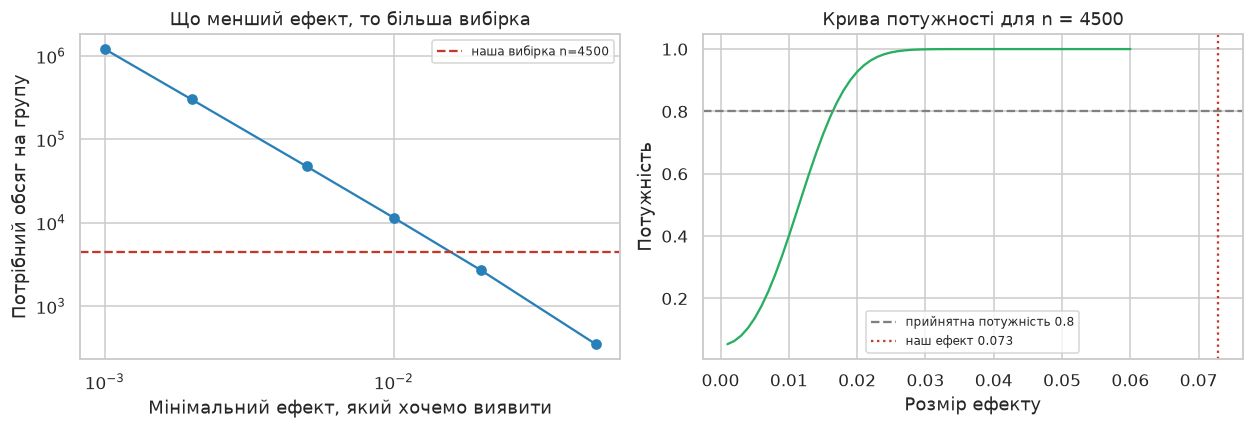

In [15]:
# --- Рисунок 5: потужність ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(power_df["Мін. ефект (MDE)"], power_df["Потрібно на групу"], "o-", color="#2980b9")
axes[0].axhline(n, color="#c0392b", linestyle="--", label=f"наша вибірка n={n}")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Мінімальний ефект, який хочемо виявити")
axes[0].set_ylabel("Потрібний обсяг на групу")
axes[0].set_title("Що менший ефект, то більша вибірка"); axes[0].legend(fontsize=8)

# крива потужності для нашого n
effects = np.linspace(0.001, 0.06, 60)
powers = []
for e in effects:
    se_ = np.sqrt(2 * pA * (1 - pA) / n)
    z_crit = stats.norm.ppf(1 - 0.025)
    powers.append(1 - stats.norm.cdf(z_crit - e/se_) + stats.norm.cdf(-z_crit - e/se_))
axes[1].plot(effects, powers, color="#27ae60")
axes[1].axhline(0.8, color="gray", linestyle="--", label="прийнятна потужність 0.8")
axes[1].axvline(pB - pA, color="#c0392b", linestyle=":", label=f"наш ефект {pB-pA:.3f}")
axes[1].set_xlabel("Розмір ефекту"); axes[1].set_ylabel("Потужність")
axes[1].set_title(f"Крива потужності для n = {n}"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "05-power.png", bbox_inches="tight")
plt.show()

## 2.4 Проблема «підглядання» (peeking)

Типова помилка на практиці: дивитись на p-значення в міру накопичення даних і
зупиняти експеримент, щойно воно опуститься нижче 0.05. Це різко підвищує частку
хибних відкриттів, бо кожна перевірка — окремий шанс випадково перетнути поріг.

Змоделюємо: **обидва варіанти однакові** ($H_0$ істинна), але ми перевіряємо
p-значення багато разів упродовж експерименту.

In [16]:
def peeking_simulation(n_total=5000, n_peeks=20, n_sims=1000, p=0.9, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    checkpoints = np.linspace(n_total // n_peeks, n_total, n_peeks).astype(int)
    false_pos_peek = 0
    false_pos_final = 0
    for _ in range(n_sims):
        a = rng.rand(n_total) < p      # обидва варіанти НАСПРАВДІ однакові
        b_ = rng.rand(n_total) < p
        significant = False
        for cp in checkpoints:
            pa, pb = a[:cp].mean(), b_[:cp].mean()
            pp = (a[:cp].sum() + b_[:cp].sum()) / (2*cp)
            se_ = np.sqrt(pp*(1-pp)*(2/cp)) or 1e-12
            if abs((pb-pa)/se_) > 1.96:
                significant = True
                break
        false_pos_peek += significant
        pa, pb = a.mean(), b_.mean()
        pp = (a.sum() + b_.sum()) / (2*n_total)
        se_ = np.sqrt(pp*(1-pp)*(2/n_total)) or 1e-12
        false_pos_final += abs((pb-pa)/se_) > 1.96
    return false_pos_peek/n_sims, false_pos_final/n_sims

rate_peek, rate_final = peeking_simulation()
print(f"Хибнопозитивні за одноразової перевірки в кінці: {rate_final:.1%}  (очікувано ≈5 %)")
print(f"Хибнопозитивні за 20 перевірок упродовж:        {rate_peek:.1%}")
print(f"Підвищення ризику: у {rate_peek/max(rate_final,1e-9):.1f}× разів")

Хибнопозитивні за одноразової перевірки в кінці: 5.3%  (очікувано ≈5 %)
Хибнопозитивні за 20 перевірок упродовж:        24.5%
Підвищення ризику: у 4.6× разів


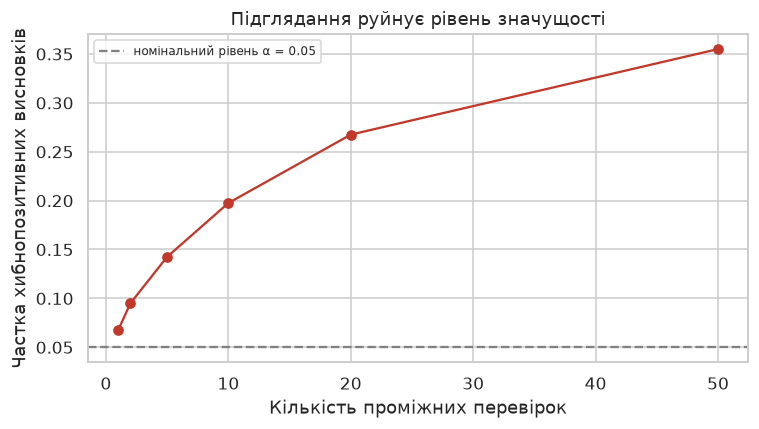

,Перевірок,Хибнопозитивних
0,1,0.0675
1,2,0.0950
2,5,0.1425
3,10,0.1975
4,20,0.2675
5,50,0.3550


In [17]:
# --- Рисунок 6: підглядання ---
peek_counts = [1, 2, 5, 10, 20, 50]
rates = [peeking_simulation(n_peeks=k, n_sims=400)[0] for k in peek_counts]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(peek_counts, rates, "o-", color="#c0392b")
ax.axhline(0.05, color="gray", linestyle="--", label="номінальний рівень α = 0.05")
ax.set_xlabel("Кількість проміжних перевірок")
ax.set_ylabel("Частка хибнопозитивних висновків")
ax.set_title("Підглядання руйнує рівень значущості")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "06-peeking.png", bbox_inches="tight")
plt.show()

pd.DataFrame({"Перевірок": peek_counts, "Хибнопозитивних": rates}).round(4)

## 3. Підсумок

In [18]:
summary = pd.DataFrame({
    "Показник": [
        "DBSCAN, найкращий ARI",
        "k-середніх, ARI (ПЗ № 6)",
        "DBSCAN, lift шуму щодо класу A",
        "A/B: точність варіанта A",
        "A/B: точність варіанта B",
        "A/B: p-значення (z-тест)",
        "A/B: p-значення (Мак-Немар)",
        "Хибнопозитивних за 20 підглядань",
    ],
    "Значення": [
        f"{db_df['ARI'].max():.4f}", "0.2010",
        f"{anom_df['Lift'].max():.2f}×",
        f"{pA:.4f}", f"{pB:.4f}",
        f"{p_value:.2e}", f"{p_mcnemar:.2e}",
        f"{rate_peek:.1%}",
    ],
}).set_index("Показник")
summary.to_csv("data/results-summary.csv")
print(summary.to_string())
print(); print("DBSCAN на синтетичних наборах:"); print(synth_df.round(4).to_markdown())

                                  Значення
Показник                                  
DBSCAN, найкращий ARI               0.0837
k-середніх, ARI (ПЗ № 6)            0.2010
DBSCAN, lift шуму щодо класу A       1.42×
A/B: точність варіанта A            0.9158
A/B: точність варіанта B            0.9887
A/B: p-значення (z-тест)          0.00e+00
A/B: p-значення (Мак-Немар)       0.00e+00
Хибнопозитивних за 20 підглядань     24.5%

DBSCAN на синтетичних наборах:
| Набір             |   k-середніх (ARI) |   DBSCAN (ARI) |
|:------------------|-------------------:|---------------:|
| Місяці            |             0.4841 |              1 |
| Кола              |            -0.0006 |              1 |
| Кулясті скупчення |             1      |              1 |
